In [2]:
import pandas as pd

df = pd.read_csv("../dataset/stores_sales_forecasting.csv", encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
3,6,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
4,11,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092


In [3]:
df.shape

(2121, 21)

In [4]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [5]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

df["Order Date"].head()

0   2016-11-08
1   2016-11-08
2   2015-10-11
3   2014-06-09
4   2014-06-09
Name: Order Date, dtype: datetime64[us]

In [8]:
monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
    .reset_index()
)

monthly_sales["Order Date"] = monthly_sales["Order Date"].dt.to_timestamp()

monthly_sales.head()

,Order Date,Sales
0,2014-01-01,6242.525
1,2014-02-01,1839.658
2,2014-03-01,14573.956
3,2014-04-01,7944.837
4,2014-05-01,6912.787


In [10]:
monthly_sales["Time_Index"] = range(len(monthly_sales))

monthly_sales.head()

,Order Date,Sales,Time_Index
0,2014-01-01,6242.525,0
1,2014-02-01,1839.658,1
2,2014-03-01,14573.956,2
3,2014-04-01,7944.837,3
4,2014-05-01,6912.787,4


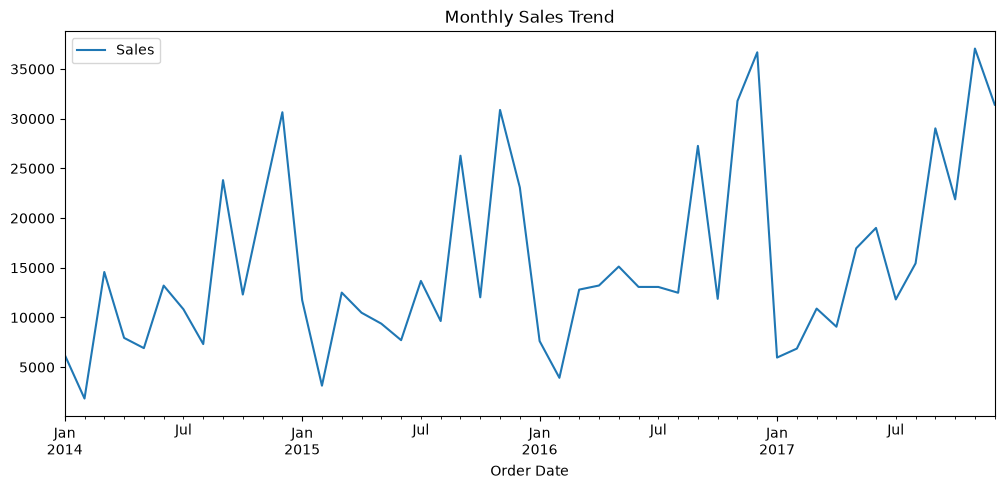

In [11]:
monthly_sales.plot(
    x="Order Date",
    y="Sales",
    figsize=(12, 5),
    title="Monthly Sales Trend"
);

In [12]:
yearly_sales = (
    df.groupby(df["Order Date"].dt.year)["Sales"]
    .sum()
    .reset_index()
)

yearly_sales

,Order Date,Sales
0,2014,157192.8531
1,2015,170518.2370
2,2016,198901.4360
3,2017,215387.2692


In [13]:
highest_month = monthly_sales.loc[monthly_sales["Sales"].idxmax()]
lowest_month = monthly_sales.loc[monthly_sales["Sales"].idxmin()]

print("Highest Sales Month:")
print(highest_month)

print("\nLowest Sales Month:")
print(lowest_month)

Highest Sales Month:
Order Date    2017-11-01 00:00:00
Sales                   37056.715
Time_Index                     46
Name: 46, dtype: object

Lowest Sales Month:
Order Date    2014-02-01 00:00:00
Sales                    1839.658
Time_Index                      1
Name: 1, dtype: object


In [15]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 2.4 MB/s eta 0:00:04
   ----- ---------------------------------- 1.0/8.4 MB 2.5 MB/s eta 0:00:03
   ------- -------------------------------- 1.6/8.4 MB 2.7 MB/s eta 0:00:03
   ----------- ---------------------------- 2.4/8.4 MB 2.9 MB/s eta 0:00:03
   --------------- ------------------------ 3.1/8.4 MB 3.2 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.4 MB 2.9 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.4 MB 3.1 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.4 MB 3.1 MB/s eta 0:00:02
   ------------------------------ --------- 6.3/8.4 MB 3.3 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.4 MB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 3.6 MB/s  0:00:02
   --------------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
from sklearn.linear_model import LinearRegression

In [17]:
X = monthly_sales[["Time_Index"]]
y = monthly_sales["Sales"]

X.head()

,Time_Index
0,0
1,1
2,2
3,3
4,4


In [18]:
model = LinearRegression()

model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[257.47]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Time_Index']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9408
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [19]:
monthly_sales["Predicted_Sales"] = model.predict(X)

monthly_sales.head()

,Order Date,Sales,Time_Index,Predicted_Sales
0,2014-01-01,6242.525,0,9407.827135
1,2014-02-01,1839.658,1,9665.295302
2,2014-03-01,14573.956,2,9922.763470
3,2014-04-01,7944.837,3,10180.231637
4,2014-05-01,6912.787,4,10437.699804


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y, monthly_sales["Predicted_Sales"])
rmse = np.sqrt(mean_squared_error(y, monthly_sales["Predicted_Sales"]))
r2 = r2_score(y, monthly_sales["Predicted_Sales"])

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 6655.949168920294
RMSE: 8272.267431152599
R² Score: 0.156768092794336


In [21]:
future_periods = 12

future_index = range(
    len(monthly_sales),
    len(monthly_sales) + future_periods
)

future_dates = pd.date_range(
    start=monthly_sales["Order Date"].max() + pd.offsets.MonthBegin(1),
    periods=future_periods,
    freq="MS"
)

future_sales = pd.DataFrame({
    "Order Date": future_dates,
    "Time_Index": future_index
})

future_sales["Forecasted_Sales"] = model.predict(
    future_sales[["Time_Index"]]
)

future_sales

,Order Date,Time_Index,Forecasted_Sales
0,2018-01-01,48,21766.299170
1,2018-02-01,49,22023.767338
2,2018-03-01,50,22281.235505
3,2018-04-01,51,22538.703672
4,2018-05-01,52,22796.171840
5,2018-06-01,53,23053.640007
6,2018-07-01,54,23311.108175
7,2018-08-01,55,23568.576342
8,2018-09-01,56,23826.044509
9,2018-10-01,57,24083.512677


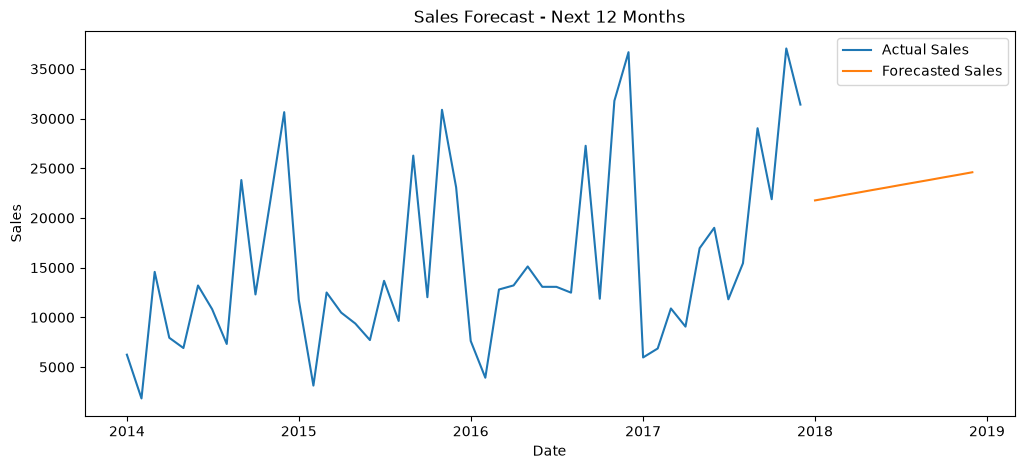

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"],
    label="Actual Sales"
)

plt.plot(
    future_sales["Order Date"],
    future_sales["Forecasted_Sales"],
    label="Forecasted Sales"
)

plt.title("Sales Forecast - Next 12 Months")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()

plt.show()

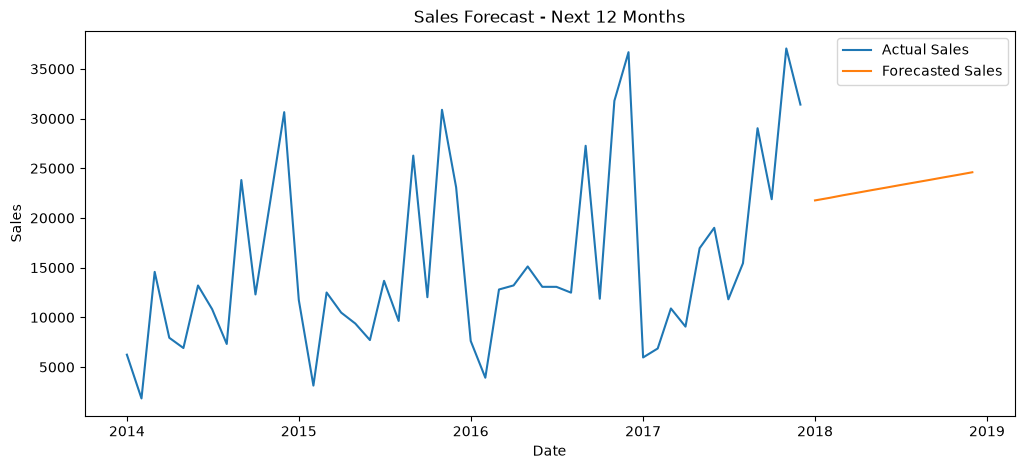

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"],
    label="Actual Sales"
)

plt.plot(
    future_sales["Order Date"],
    future_sales["Forecasted_Sales"],
    label="Forecasted Sales"
)

plt.title("Sales Forecast - Next 12 Months")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()

plt.savefig("../Visualizations/sales_forecast.png", dpi=300, bbox_inches="tight")

plt.show()

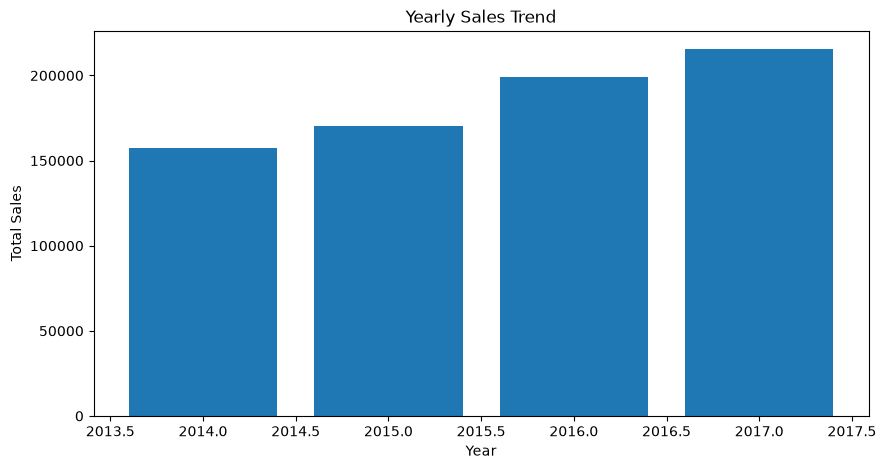

In [24]:
plt.figure(figsize=(10, 5))

plt.bar(
    yearly_sales["Order Date"],
    yearly_sales["Sales"]
)

plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.show()

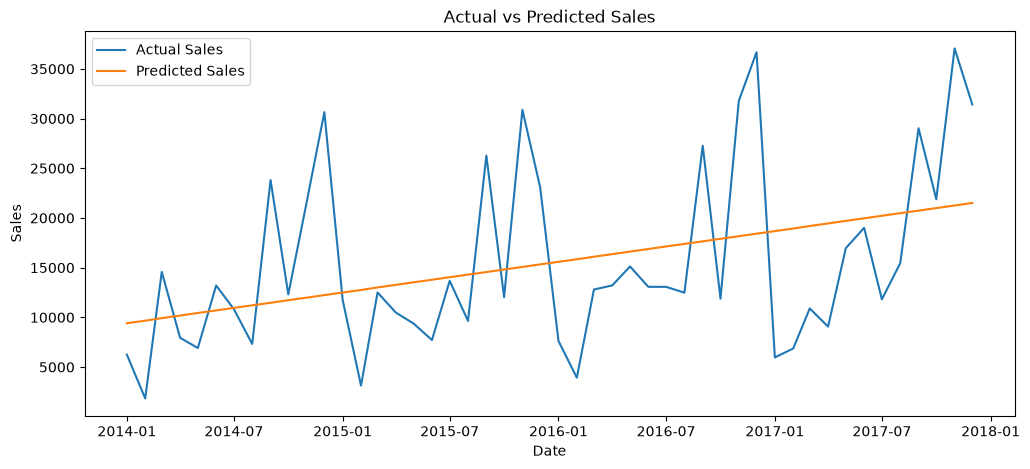

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"],
    label="Actual Sales"
)

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Predicted_Sales"],
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()

plt.show()

In [26]:
monthly_sales.to_csv(
    "../dataset/monthly_sales_cleaned.csv",
    index=False
)

future_sales.to_csv(
    "../dataset/future_sales_forecast.csv",
    index=False
)

print("Files saved successfully!")

Files saved successfully!
